# Task 3: SQL queries and initial performance results

The queries live in `Task 3/queries.sql` (the supplementary `.sql` file). This notebook reads them from there, runs each one, shows the result, and measures runtimes.

## What Task 3 requires

| # | Requirement | Where in this notebook |
|---|---|---|
| 1 | SQL for Q1–Q5 (Appendix A) and an own Q6 that joins **all** tables | `queries.sql`, Part A |
| 2 | Run each query; check the result matches the requirement | Part A |
| 3 | At least **one insight per query** | Part A, "Insight" cells (to fill in) |
| 4 | Screenshots of the query results | Part A outputs |
| 5 | Run each query **5 times**, record each runtime, compute the average | Part B |
| 6 | Repeat for **5 database sizes**, adding one resale file at a time; record the database size each time | Part B, once per step |
| 7 | **150 measurements** in total (6 queries × 5 runs × 5 sizes) in a raw file | `Task 3/results/task3_measurements.csv` |
| 8 | Plot database size vs runtime for each query, and interpret it | Part C |

## The 5 database sizes

| Step | Resale files loaded | Transactions (approx.) |
|---|---|---|
| 1 | Jan 2017 onwards | 241,483 |
| 2 | + Jan 2015 – Dec 2016 | 278,636 |
| 3 | + Mar 2012 – Dec 2014 | 330,839 |
| 4 | + 2000 – Feb 2012 | 700,490 |
| 5 | + 1990 – 1999 | 987,686 |

For each step: load the database with that step's files (Task 2 revised notebook with those files in `RESALE_FILES`, then `schema.sql` + the COPY statements), set `STEP` below, and run the notebook.

## Setup
Set `DB_NAME` to the database that holds the `housing` schema, and `STEP` to the database size you are measuring (1–5).

In [26]:
import os
import re
import time
from datetime import datetime
from pathlib import Path

import pandas as pd
import psycopg
import matplotlib.pyplot as plt

DB_NAME = "kuberbellad04"   # database that holds the housing schema
STEP = int(os.environ.get("TASK3_STEP", 4))   # database size being measured: 1-5 (or set TASK3_STEP)
RUNS = 5                    # runs per query

# repository root: the first folder, going upwards, that contains "Task 3"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Task 3").is_dir())
QUERY_FILE = ROOT / "Task 3" / "queries.sql"
RESULTS = ROOT / "Task 3" / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
MEASUREMENTS = RESULTS / "task3_measurements.csv"   # raw file: one row per run
SUMMARY = RESULTS / "task3_summary.csv"             # average per query and step
PLOT = RESULTS / "task3_runtime_vs_size.png"

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

con = psycopg.connect(dbname=DB_NAME, autocommit=True)
print("connected to", DB_NAME, "| step", STEP)

connected to kuberbellad04 | step 4


## Helpers
- `QUERIES`: the six queries, read from `queries.sql` (each starts with a `-- @Qn` line).
- `run_query`: runs one query and returns the result as a DataFrame and the runtime in milliseconds.
- `db_snapshot`: the size of the database at this step.

**How runtime is measured:** wall-clock time from sending the query until all result rows have been received (`time.perf_counter` around `execute` + `fetchall`). This is the same thing pgAdmin reports as the query time.

In [27]:
QUERIES = dict(re.findall(r"-- @(Q\d)\n(.*?)(?=\n-- @Q\d|\Z)", QUERY_FILE.read_text(), flags=re.S))
print("queries loaded:", list(QUERIES))


def run_query(name):
    """Run one query; return (result DataFrame, runtime in ms)."""
    start = time.perf_counter()
    cur = con.execute(QUERIES[name])
    rows = cur.fetchall()
    ms = (time.perf_counter() - start) * 1000
    return pd.DataFrame(rows, columns=[d.name for d in cur.description]), ms


def db_snapshot():
    """Size of the database at this step."""
    return con.execute("""
        SELECT (SELECT count(*) FROM housing.resale_transaction)          AS transactions,
               (SELECT min(transaction_month) FROM housing.resale_transaction) AS first_month,
               (SELECT max(transaction_month) FROM housing.resale_transaction) AS last_month,
               pg_database_size(current_database())                        AS db_size_bytes,
               (SELECT sum(pg_total_relation_size(c.oid))
                FROM pg_class c JOIN pg_namespace n ON n.oid = c.relnamespace
                WHERE n.nspname = 'housing' AND c.relkind = 'r')            AS housing_size_bytes
    """).fetchone()

queries loaded: ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6']


## Pre-check: is the database complete?
Every table must have rows; `proximity` in particular, otherwise Q4–Q6 return nothing.

In [28]:
counts = con.execute("""
    SELECT 'town' AS table_name, count(*) AS row_count FROM housing.town
    UNION ALL SELECT 'hdb_building',       count(*) FROM housing.hdb_building
    UNION ALL SELECT 'hdb_flat',           count(*) FROM housing.hdb_flat
    UNION ALL SELECT 'resale_transaction', count(*) FROM housing.resale_transaction
    UNION ALL SELECT 'hawker_centre',      count(*) FROM housing.hawker_centre
    UNION ALL SELECT 'proximity_level',    count(*) FROM housing.proximity_level
    UNION ALL SELECT 'proximity',          count(*) FROM housing.proximity
""").fetchall()
display(pd.DataFrame(counts, columns=["table", "rows"]))
empty = [t for t, n in counts if n == 0]
if empty:
    print("WARNING: empty tables:", empty, "- load them before measuring")

transactions, first_month, last_month, db_bytes, housing_bytes = db_snapshot()
print(f"transactions: {transactions:,} ({first_month} to {last_month})")
print(f"database size: {db_bytes / 2**20:.1f} MB | housing tables incl. indexes: {housing_bytes / 2**20:.1f} MB")

,table,rows
0,town,26
1,hdb_building,9957
2,hdb_flat,139883
3,resale_transaction,700490
4,hawker_centre,131
5,proximity_level,3
6,proximity,30731


transactions: 700,490 (2000-01-01 to 2026-09-01)
database size: 82.4 MB | housing tables incl. indexes: 74.3 MB


# Part A: run each query and look at the result

Each query runs once here so you can check the result and take a screenshot. Under each result, write at least one insight. An insight can also be the absence of an expected effect, e.g. "from this result alone we cannot conclude that X affects Y".

## Q1: Price per square metre across towns
Average price per m² of **4-room and 5-room** flats sold in the 3-year range **2022–2024**, per town and flat type.

In [29]:
result, ms = run_query("Q1")
print(f"Q1: {len(result)} rows in {ms:.1f} ms")
display(result)

Q1: 52 rows in 60.6 ms


,town_name,flat_type,avg_price_per_sqm,transactions
0,ANG MO KIO,4 ROOM,6818.39,957
1,ANG MO KIO,5 ROOM,7067.23,422
2,BEDOK,4 ROOM,6031.59,1364
3,BEDOK,5 ROOM,5925.26,723
4,BISHAN,4 ROOM,7098.51,586
5,BISHAN,5 ROOM,7544.95,347
6,BUKIT BATOK,4 ROOM,6116.90,1823
7,BUKIT BATOK,5 ROOM,6423.57,723
8,BUKIT MERAH,4 ROOM,8585.31,1219
9,BUKIT MERAH,5 ROOM,7861.56,584


**What to look for:** Which towns are the most / least expensive per m²? How large is the gap? Is a 5-room flat more expensive per m² than a 4-room flat in the same town?

**Insight (Q1):** _to fill in_

## Q2: Remaining lease vs transaction price
Sales grouped into remaining-lease buckets (< 50, 50–69, 70–89, 90+ years) with a `CASE` expression. Per town and bucket: median resale price, average price per m², number of sales. Remaining lease = 99 − (sale year − lease start year), derived for every sale.

In [30]:
result, ms = run_query("Q2")
print(f"Q2: {len(result)} rows in {ms:.1f} ms")
display(result)

Q2: 88 rows in 316.3 ms


,town_name,lease_bucket,median_resale_price,avg_price_per_sqm,transaction_volume
0,ANG MO KIO,1: < 50 years,417944.0,5863.97,20
1,ANG MO KIO,2: 50-69 years,362000.0,4801.47,15130
2,ANG MO KIO,3: 70-89 years,200500.0,3000.76,16717
3,ANG MO KIO,4: 90+ years,595000.0,6449.17,2012
4,BEDOK,1: < 50 years,380000.0,5626.75,132
5,BEDOK,2: 50-69 years,365000.0,4712.80,18032
6,BEDOK,3: 70-89 years,222000.0,3110.44,21242
7,BEDOK,4: 90+ years,430000.0,4902.99,3074
8,BISHAN,1: < 50 years,366944.0,5363.83,54
9,BISHAN,2: 50-69 years,665000.0,6380.24,3385


**What to look for:** Does the median price rise with remaining lease in most towns? Which buckets have very few sales (and so unreliable medians)? Which towns have no old or no new flats?

**Insight (Q2):** _to fill in_

## Q3: Resale price for towns with large flats
The **10 towns** with the highest average floor area of 3-room flats sold (`LIMIT 10`), and for each of them the highest 3-room resale price per year (`WITH` subqueries).

In [31]:
result, ms = run_query("Q3")
print(f"Q3: {len(result)} rows in {ms:.1f} ms")
display(result)

Q3: 270 rows in 100.9 ms


,town_name,avg_floor_area_sqm,sale_year,max_resale_price
0,TAMPINES,72.21,2000,265000.00
1,TAMPINES,72.21,2001,230000.00
2,TAMPINES,72.21,2002,233000.00
3,TAMPINES,72.21,2003,238000.00
4,TAMPINES,72.21,2004,250000.00
5,TAMPINES,72.21,2005,250000.00
6,TAMPINES,72.21,2006,235000.00
7,TAMPINES,72.21,2007,290000.00
8,TAMPINES,72.21,2008,295000.00
9,TAMPINES,72.21,2009,322000.00


**What to look for:** How different are the average floor areas really? Does the town with the largest flats also have the highest prices? How did the maximum price change over the years?

**Insight (Q3):** _to fill in_

## Q4: Hawker centre proximity effect
Average price of flats whose nearest hawker centre is in the closest class (**Walking distance, < 800 m**) vs the furthest class (**Accessible, 1,600–2,400 m**), per town and flat type, with `price_diff_percentage = (near − far) × 100 / far`. Only groups with sales in both classes are shown.

In [32]:
result, ms = run_query("Q4")
print(f"Q4: {len(result)} rows in {ms:.1f} ms")
display(result)

Q4: 68 rows in 137.3 ms


,town,flat_type,avg_price_near_hawker,avg_price_far_hawker,price_diff_percentage
0,BEDOK,EXECUTIVE,621518.56,586722.89,5.93
1,BISHAN,3 ROOM,278200.17,311103.97,-10.58
2,BISHAN,4 ROOM,405918.97,463727.59,-12.47
3,BISHAN,5 ROOM,582304.12,605780.11,-3.88
4,BISHAN,EXECUTIVE,810714.32,746260.93,8.64
5,BUKIT BATOK,3 ROOM,320435.53,230882.91,38.79
6,BUKIT BATOK,4 ROOM,573119.07,340170.33,68.48
7,BUKIT BATOK,5 ROOM,688404.21,515650.53,33.50
8,BUKIT MERAH,5 ROOM,688893.88,603817.27,14.09
9,BUKIT PANJANG,2 ROOM,299006.97,277004.18,7.94


**What to look for:** In how many groups is near more expensive than far, and in how many less? Is there a consistent effect, or does it depend on town / flat type? What else could explain the differences (location, flat age)?

**Insight (Q4):** _to fill in_

## Q5: Town-level price near fresh-market hawkers
For flats near a hawker centre **with market produce stalls** (`market_produce_stalls > 0`): average price per proximity class of the nearest such centre, for towns whose overall average exceeds the **budget of SGD 450,000**. 450,000 was chosen so that the result is neither empty nor all towns at every database size (2–20 of the 22 towns with market-near flats).

In [35]:
result, ms = run_query("Q5")
print(f"Q5: {len(result)} rows in {ms:.1f} ms")
display(result)

Q5: 0 rows in 318.2 ms


,town,proximity_class,avg_resale_price,transactions


**What to look for:** How many towns pass the budget? Within those towns, are flats closest to a market more or less expensive than flats further away?

**Insight (Q5):** _to fill in_

## Q6: Own query (joins all 7 tables): does the type of the nearest hawker centre matter?
For 4-room flats sold 2022–2024: average price per m² by proximity class **and type** of the nearest centre (HC = hawker centre, MHC = market & hawker centre, MK = market, UNKNOWN = only in `hawker_geo.csv`). Joins resale_transaction, hdb_flat, hdb_building, town, proximity, hawker_centre and proximity_level.

In [34]:
result, ms = run_query("Q6")
print(f"Q6: {len(result)} rows in {ms:.1f} ms")
display(result)

Q6: 11 rows in 76.8 ms


,proximity_class,nearest_centre_type,towns,transactions,avg_price_per_sqm
0,Walking distance,HC,9,320,7169.33
1,Walking distance,MHC,19,6811,7211.02
2,Walking distance,MK,1,381,9064.36
3,Walking distance,UNKNOWN,15,5916,5960.58
4,Nearby,HC,5,153,6069.65
5,Nearby,MHC,17,3300,6536.73
6,Nearby,MK,2,20,8111.05
7,Nearby,UNKNOWN,16,10282,5883.99
8,Accessible,HC,1,22,5306.44
9,Accessible,MHC,12,641,5907.31


**What to look for:** Does price per m² fall with distance for every centre type? Are flats near markets priced differently? Which groups are too small to trust?

**Insight (Q6):** _to fill in_

# Part B: runtime measurements for this database size

Runs every query `RUNS` (5) times in a row on the current database and appends one row per run to `Task 3/results/task3_measurements.csv`:

| Column | Meaning |
|---|---|
| `step` | database size step (1–5) |
| `transactions`, `first_month`, `last_month` | how much resale data is loaded |
| `db_size_mb` | `pg_database_size` of the whole database |
| `housing_size_mb` | the 7 housing tables incl. their indexes |
| `query`, `run` | which query, run 1–5 |
| `runtime_ms` | wall-clock runtime of that run |
| `rows_returned` | rows in the result (should be the same in all 5 runs) |
| `measured_at` | timestamp |

Re-running this cell for the same `STEP` **replaces** that step's rows, so the file never holds duplicates.

Note: run 1 is often slower than runs 2–5 because the data is not yet in memory (cold cache). All 5 runs are kept and averaged, as the brief asks.

In [23]:
transactions, first_month, last_month, db_bytes, housing_bytes = db_snapshot()
records = []
for name in QUERIES:
    for run in range(1, RUNS + 1):
        result, ms = run_query(name)
        records.append({
            "step": STEP, "transactions": transactions, "first_month": first_month, "last_month": last_month,
            "db_size_mb": round(db_bytes / 2**20, 2), "housing_size_mb": round(housing_bytes / 2**20, 2),
            "query": name, "run": run, "runtime_ms": round(ms, 3), "rows_returned": len(result),
            "measured_at": datetime.now().isoformat(timespec="seconds"),
        })
    print(f"{name}: " + ", ".join(f"{r['runtime_ms']:.1f}" for r in records[-RUNS:]) + " ms")

new = pd.DataFrame(records)
if MEASUREMENTS.exists():
    old = pd.read_csv(MEASUREMENTS)
    new = pd.concat([old[old["step"] != STEP], new], ignore_index=True)
new = new.sort_values(["step", "query", "run"])
new.to_csv(MEASUREMENTS, index=False)
print(f"\nsaved {len(records)} measurements for step {STEP}; file now has {len(new)} rows "
      f"(target: 150 = 6 queries x 5 runs x 5 sizes)")

Q1: 21.4, 22.0, 20.8, 21.7, 21.5 ms
Q2: 229.1, 225.3, 222.3, 225.7, 223.4 ms
Q3: 49.6, 49.7, 50.0, 49.6, 50.3 ms
Q4: 92.2, 85.5, 92.5, 86.6, 88.6 ms
Q5: 136.4, 136.5, 139.8, 140.0, 137.8 ms
Q6: 43.7, 42.7, 43.5, 42.8, 42.2 ms

saved 30 measurements for step 3; file now has 90 rows (target: 150 = 6 queries x 5 runs x 5 sizes)


### Averages so far
Average and standard deviation of the 5 runs per query and step; saved to `Task 3/results/task3_summary.csv`.

In [24]:
m = pd.read_csv(MEASUREMENTS)
summary = (m.groupby(["step", "transactions", "db_size_mb", "housing_size_mb", "query"])["runtime_ms"]
             .agg(avg_runtime_ms="mean", std_runtime_ms="std", min_runtime_ms="min", max_runtime_ms="max", runs="count")
             .round(2).reset_index())
summary.to_csv(SUMMARY, index=False)
display(summary.pivot(index="query", columns="step", values="avg_runtime_ms"))
print("steps measured:", sorted(m["step"].unique()), "| measurements:", len(m), "of 150")

step,1,2,3
query,,,
Q1,31.39,31.78,21.49
Q2,169.89,195.49,225.17
Q3,37.90,38.20,49.85
Q4,74.72,84.45,89.09
Q5,111.58,127.92,138.08
Q6,39.76,40.33,43.00


steps measured: [np.int64(1), np.int64(2), np.int64(3)] | measurements: 90 of 150


# Part C: database size vs runtime

One small chart per query: the line is the average runtime at each database size, the faint dots are the 5 individual runs. Each query has its own y-axis, because their runtimes differ a lot; compare the **shape** of the lines (flat, linear, steeper than linear), not their heights. Saved to `Task 3/results/task3_runtime_vs_size.png` for the report.

Run this after every step; the chart fills in as more steps are measured.

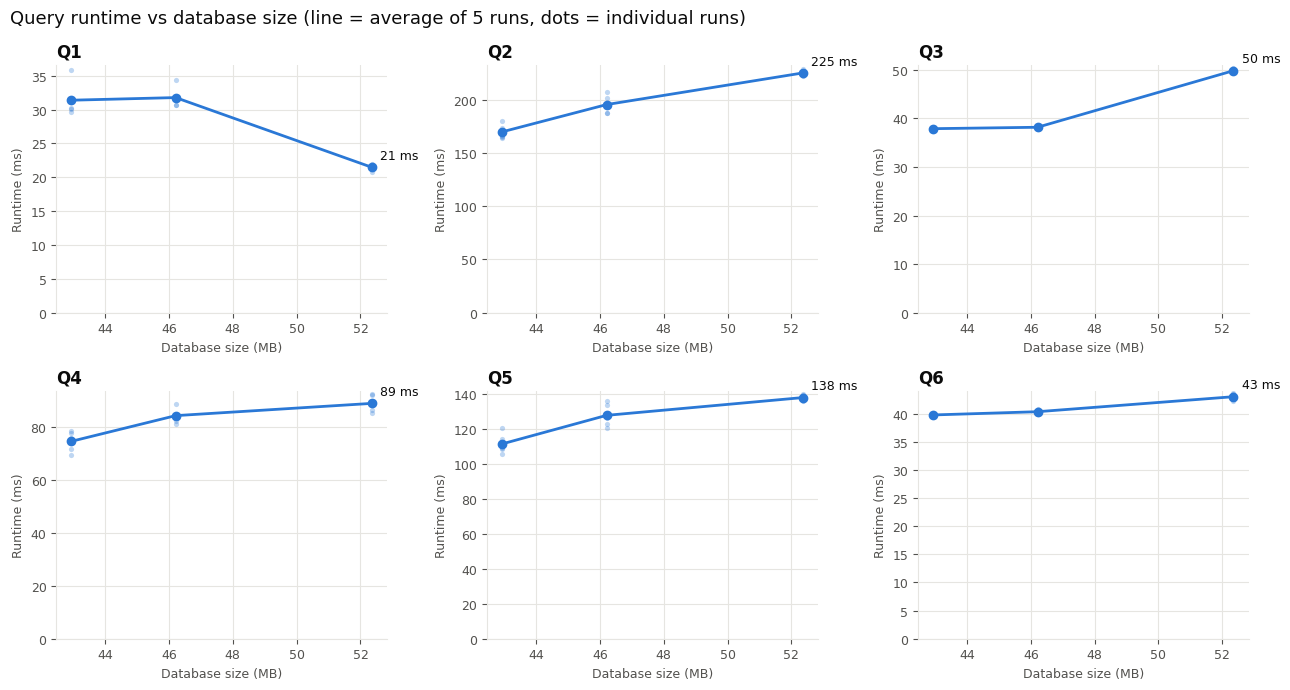

In [25]:
m = pd.read_csv(MEASUREMENTS)
avg = m.groupby(["query", "db_size_mb"], as_index=False)["runtime_ms"].mean()

LINE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e6e5e1"
fig, axes = plt.subplots(2, 3, figsize=(13, 7), facecolor="white")
for ax, name in zip(axes.flat, sorted(m["query"].unique())):
    runs = m[m["query"] == name]
    a = avg[avg["query"] == name].sort_values("db_size_mb")
    ax.scatter(runs["db_size_mb"], runs["runtime_ms"], s=14, color=LINE, alpha=0.3, linewidths=0)
    ax.plot(a["db_size_mb"], a["runtime_ms"], color=LINE, linewidth=2, marker="o", markersize=6)
    last = a.iloc[-1]
    ax.annotate(f"{last['runtime_ms']:.0f} ms", (last["db_size_mb"], last["runtime_ms"]),
                xytext=(6, 6), textcoords="offset points", fontsize=9, color=INK)
    ax.set_title(name, loc="left", fontsize=12, fontweight="bold", color=INK)
    ax.set_ylim(bottom=0)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.set_xlabel("Database size (MB)", color=MUTED, fontsize=9)
    ax.set_ylabel("Runtime (ms)", color=MUTED, fontsize=9)
fig.suptitle("Query runtime vs database size (line = average of 5 runs, dots = individual runs)",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout()
fig.savefig(PLOT, dpi=200)
plt.show()

## Interpretation (to fill in after all 5 steps)
- How does runtime grow with database size for each query: roughly flat, linear, or faster than linear?
- Which queries grow fastest, and why? (Look at what each query must scan, join, sort or aggregate; e.g. Q2's median needs a sort per group, Q1/Q6 filter on 2022–2024 but still scan the whole table without an index.)
- Is the variation between the 5 runs small compared with the differences between sizes?
- These observations are the starting point for Task 4 (indexes).

In [13]:
con.close()